# Pilot v2: does machine precision limit training of multi-dimensional angle encodings?

**Why v2.** Pilot v1 established a clean *coefficient-level* law for unary encodings (tangent row norm $r_\omega\propto\rho_\omega^{0.62}$, collapse across $d$, f32 floor confirmed cell by cell). Its *training* test could not decide the question: in a realizable teacher–student started near the teacher, low-redundancy cells are corrected as a by-product of the high-redundancy cells, so no cell ever needs a gradient below the floor. v1 also found that random-init training stalls at $d\gtrsim3$ at a stationary point, which is neither precision nor step budget.

**Design rule for v2.** In the core tests, precision is the only thing that can differ between arms. Every other limit gets its own control.

| Part | Question | Isolation |
|---|---|---|
| **D1** | Is the gradient signal of one target component resolvable in precision $p$? | No training. Inject amplitude $\varepsilon\,\mathrm{std}(f)$ in one cell at the teacher $\theta^*$; compare the gradient in bf16/f16/f32 with the exact f64 gradient. One law, fitted on f32 only, must predict bf16 and f16. |
| **D2** | Is any *parameter direction* lost to precision? (unary deg 5, $d$ sweep) | Singular values of the data Jacobian computed in $p$ vs f64; Weyl bound $\varepsilon_p\sigma_1/\sigma_k$. Structural null directions reported separately. |
| **E** | Does the optimiser pick up an injected cell? | Start at $\theta^*$, so the only signal is the injected cell. Learned fraction $\eta=q/q_{\rm lin}$ (normalised by the first-order reachable part). GD is compared with **exact f64 linear theory** (no fitting). A Levenberg–Marquardt oracle run entirely in $p$ isolates precision from conditioning. Paired f32 vs f64 per cell, with a **power check**: the test can only show a precision effect on cells that f64 learns and that lie below the f32 visibility threshold. |
| **F** | Is the random-init stall an under-parameterisation trap? | Fixed teacher (1 block/layer); student with 1, 2, 4, 8 trainable blocks per layer at the same degree. |
| **G** | Are trainable frequencies worth it? | Off-lattice teacher with **additive** prefactor offsets $U[-\delta,\delta]$, $\delta$ swept across the ±½ leash; $\theta$ init near the teacher (prefactor transport alone) and random (realistic). Records whether each prefactor reached the teacher's value. |

**Pre-registered verdicts (printed in the last cell).**
- **V1** law holds if the slope of measured vs predicted log-error is $1\pm0.15$ for all precisions and bf16/f16 residuals are within 2 bits of a law fitted on f32 only.
- **V3** precision binds training iff, on cells that f64 learns ($\eta>0.5$) and that lie below the f32 visibility threshold, the paired median $|\eta_{f32}-\eta_{f64}|>0.2$. If fewer than 5 such cells exist, the test is declared to have **no power** (it is then not evidence for or against a precision floor).
- **V3d** the GD (step-budget) law predicts the threshold moving by about $-\tfrac12\log_2(T_2/T_1)$ bits and not with precision.

**Simulator.** Native JAX, real-split state (real and imaginary parts as separate real arrays), so every elementwise op runs in bf16, f16, f32 or f64. JAX accumulates *reductions* in f32 for 16-bit types, which makes 16-bit thresholds slightly optimistic. One qubit per feature; a block is `tbl` × [Rot on every qubit; CNOT ladder]; the circuit is block, then L × [RX(α·x) on every qubit; block]; Z readout on the last qubit. **Not identical to v1**: v1 had no CNOT ladder after the initial Rot. Layers use `lax.scan`, so compile time does not grow with L.

`QUICK=True` runs in minutes on CPU (pipeline check only, numbers not meaningful). `QUICK=False` is intended for `qtgpu`. Every part caches to `RESULTS_DIR` and resumes.

In [1]:
# ---- core v2: real-split simulator that runs every op in precision p ------------------
import itertools, math, time, json, os, pickle
import numpy as np
import jax, jax.numpy as jnp
jax.config.update("jax_enable_x64", True)

DT = {"bf16": jnp.bfloat16, "f16": jnp.float16, "f32": jnp.float32, "f64": jnp.float64}
LOG2EPS = {p: float(np.log2(np.finfo(np.dtype(DT[p])).eps if p != "bf16" else 2.0 ** -7)) for p in DT}
# NOTE on 16-bit types: every elementwise op is rounded to p, but JAX accumulates *reductions*
# (sums over the 2^d amplitudes and over samples) in f32 for bf16/f16. That makes measured
# 16-bit thresholds slightly optimistic; it does not touch f32/f64.

ENC = {"unary": lambda L: [1] * L, "ternary": lambda L: [3 ** j for j in range(L)]}
def degree(ab): return int(sum(abs(a) for a in ab))

def _rx_ri(a):
    c, s = jnp.cos(a / 2), jnp.sin(a / 2); z = jnp.zeros_like(c)
    return (c, z, z, c), (z, -s, -s, z)            # (U00,U01,U10,U11) real parts, imag parts

def _rot_ri(f, t, w):  # RZ(w) RY(t) RZ(f) == PennyLane Rot(f, t, w)
    c, s = jnp.cos(t / 2), jnp.sin(t / 2)
    a, b = (f + w) / 2, (f - w) / 2
    ca, sa, cb, sb = jnp.cos(a), jnp.sin(a), jnp.cos(b), jnp.sin(b)
    re = (ca * c, -cb * s, cb * s, ca * c)
    im = (-sa * c, -sb * s, -sb * s, sa * c)
    return re, im

def _apply(pr, pi, U, q):
    (r00, r01, r10, r11), (i00, i01, i10, i11) = U
    ar, ai = jnp.moveaxis(pr, q, 0), jnp.moveaxis(pi, q, 0)
    a0r, a1r, a0i, a1i = ar[0], ar[1], ai[0], ai[1]
    n0r = r00 * a0r - i00 * a0i + r01 * a1r - i01 * a1i
    n0i = r00 * a0i + i00 * a0r + r01 * a1i + i01 * a1r
    n1r = r10 * a0r - i10 * a0i + r11 * a1r - i11 * a1i
    n1i = r10 * a0i + i10 * a0r + r11 * a1i + i11 * a1r
    return jnp.moveaxis(jnp.stack([n0r, n1r]), 0, q), jnp.moveaxis(jnp.stack([n0i, n1i]), 0, q)

def _cnot(p, c, t):
    a = jnp.moveaxis(p, (c, t), (0, 1)); a = jnp.stack([a[0], a[1][::-1]])
    return jnp.moveaxis(a, (0, 1), (c, t))

def model(x, theta, alpha):
    """x: (d,), theta: (L+1, tbl, d, 3), alpha: (L, d). Dtype of x sets the precision.
    Block = tbl x [Rot on every qubit; CNOT ladder]. Circuit: block, then L x [RX(alpha*x) on every qubit; block].
    Readout: Z on the last qubit."""
    d = x.shape[0]; L = alpha.shape[0]; tbl = theta.shape[1]; dt = x.dtype
    theta = theta.astype(dt); alpha = alpha.astype(dt)
    pr = jnp.zeros((2,) * d, dt).at[(0,) * d].set(1); pi = jnp.zeros((2,) * d, dt)
    def one_block(carry, thb):                       # thb: (d, 3)
        pr, pi = carry
        for q in range(d):
            pr, pi = _apply(pr, pi, _rot_ri(thb[q, 0], thb[q, 1], thb[q, 2]), q)
        for q in range(d - 1):
            pr, pi = _cnot(pr, q, q + 1), _cnot(pi, q, q + 1)
        return (pr, pi), None
    def block(carry, th):                            # th: (tbl, d, 3)
        return jax.lax.scan(one_block, carry, th)[0]
    def layer(carry, inp):                           # lax.scan keeps compile time independent of L
        thl, al = inp
        pr, pi = carry
        for q in range(d):
            pr, pi = _apply(pr, pi, _rx_ri(al[q] * x[q]), q)
        return block((pr, pi), thl), None
    pr, pi = block((pr, pi), theta[0])
    (pr, pi), _ = jax.lax.scan(layer, (pr, pi), (theta[1:], alpha))
    prob = (pr * pr + pi * pi).reshape(-1, 2)
    return jnp.sum(prob[:, 0] - prob[:, 1])

model_batch = jax.vmap(model, in_axes=(0, None, None))
_JAC64 = jax.jit(jax.vmap(jax.jacfwd(model, argnums=1), in_axes=(0, None, None)))
_FB = jax.jit(model_batch)

def init_theta(key, L, d, tbl=1):
    return jax.random.uniform(key, (L + 1, tbl, d, 3), minval=0.0, maxval=2 * np.pi, dtype=jnp.float64)

def alpha_array(ab, d):
    return jnp.tile(jnp.asarray(ab, dtype=jnp.float64)[:, None], (1, d))

def n_params(L, d, tbl): return 3 * d * (L + 1) * tbl

# ---------- redundancy ----------
def redundancy_1d(ab):
    K = degree(ab); w = np.zeros(2 * K + 1); w[K] = 1.0
    for a in ab:
        new = np.zeros_like(w)
        for sh, m in ((-a, 1), (0, 2), (a, 1)): new += m * np.roll(w, sh)
        w = new
    return np.arange(-K, K + 1), w / 4.0 ** len(ab)

def log2rho_of(F, ab):
    K = degree(ab); _, w = redundancy_1d(ab)
    with np.errstate(divide="ignore"): lw = np.log2(w / w.max())
    tab = np.full(2 * K + 3, -np.inf); tab[1:-1] = lw
    return tab[np.clip(F + K + 1, 0, 2 * K + 2)].sum(-1)

# ---------- grid, data Jacobian, coefficient-Jacobian row norms (all f64) ----------
def grid(K, d, M=None):
    M = M or 2 * K + 3
    g = 2 * np.pi * np.arange(M) / M
    return jnp.asarray(np.stack(np.meshgrid(*([g] * d), indexing="ij"), -1).reshape(-1, d)), M

def data_jacobian(X, theta, alpha, chunk=4096):
    Js = [_JAC64(X[i:i + chunk], theta, alpha).reshape(min(chunk, X.shape[0] - i), -1) for i in range(0, X.shape[0], chunk)]
    return jnp.concatenate(Js)                       # (N, P)

def cell_row_norms(Jd, M, d, K):
    """FFT of the data Jacobian on the grid -> per-cell row norms r_omega (in-band cells only)."""
    P = Jd.shape[1]
    C = jnp.fft.fftn(Jd.reshape((M,) * d + (P,)), axes=tuple(range(d))) / M ** d
    r = np.asarray(jnp.sqrt(jnp.sum(jnp.abs(C) ** 2, -1)))
    fr = np.fft.fftfreq(M, 1.0 / M).round().astype(int)
    F = np.stack(np.meshgrid(*([fr] * d), indexing="ij"), -1)
    inb = np.all(np.abs(F) <= K, -1)
    return F[inb], r[inb]

def pick_cells(F, r, n_per_bin, bw, lo, rng):
    """One representative per +/- omega pair, stratified in log2(r/r_max) bins; omega = 0 excluded."""
    key = lambda w: tuple(w) if tuple(w) > tuple(-w) else tuple(-w)
    seen, keep = set(), []
    for i, w in enumerate(F):
        if not np.any(w): continue
        k = key(w)
        if k in seen: continue
        seen.add(k); keep.append(i)
    keep = np.array(keep); lr = np.log2(r[keep] / r.max())
    out = []
    for b in np.arange(0, lo, -bw):
        idx = keep[(lr <= b) & (lr > b - bw)]
        if len(idx): out += list(rng.choice(idx, size=min(n_per_bin, len(idx)), replace=False))
    return np.array(out)

def injection(X, omega, phase):
    u = np.sqrt(2.0) * np.cos(np.asarray(X) @ np.asarray(omega, float) + phase)
    return u / np.sqrt(np.mean(u ** 2))

In [2]:
import pandas as pd, matplotlib.pyplot as plt, optax
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3, "font.size": 9})
COL = {"bf16": "#8e44ad", "f16": "#d68910", "f32": "#c0392b", "f64": "#2471a3"}
print("JAX", jax.__version__, "| devices:", jax.devices())

# sanity: f64 vs f32 agree, 16-bit errors at the eps scale; optional PennyLane cross-check
_k = jax.random.PRNGKey(3)
_th = init_theta(_k, 2, 2, 2); _al = alpha_array(ENC["ternary"](2), 2) * 1.07; _x = jnp.array([0.4, 2.1])
_v = {p: float(model(_x.astype(DT[p]), _th, _al)) for p in DT}
print("model outputs per precision:", {p: f"{v:.8f}" for p, v in _v.items()})
assert abs(_v["f32"] - _v["f64"]) < 1e-5 and abs(_v["f64"]) <= 1
try:
    import pennylane as qml
    _d, _L, _tbl = 2, 2, 2
    dev = qml.device("default.qubit", wires=_d)
    @qml.qnode(dev)
    def _pl(x, th, al):
        def block(t):
            for b in range(_tbl):
                for q in range(_d): qml.Rot(t[b, q, 0], t[b, q, 1], t[b, q, 2], wires=q)
                for q in range(_d - 1): qml.CNOT(wires=[q, q + 1])
        block(th[0])
        for l in range(_L):
            for q in range(_d): qml.RX(al[l, q] * x[q], wires=q)
            block(th[l + 1])
        return qml.expval(qml.PauliZ(_d - 1))
    _ref = float(_pl(np.asarray(_x), np.asarray(_th), np.asarray(_al)))
    print(f"PennyLane cross-check: |JAX f64 - PennyLane| = {abs(_ref - _v['f64']):.2e}")
    assert abs(_ref - _v["f64"]) < 1e-10
except ImportError:
    print("PennyLane not installed: cross-check skipped")

JAX 0.12.0.1 | devices: [CpuDevice(id=0)]
model outputs per precision: {'bf16': '-0.55468750', 'f16': '-0.55371094', 'f32': '-0.55729377', 'f64': '-0.55729403'}
PennyLane not installed: cross-check skipped


In [3]:
QUICK = False            # False on qtgpu
RESULTS_DIR = "results_v2_quick" if QUICK else "results_v2"
os.makedirs(RESULTS_DIR, exist_ok=True)

# ---- Part D: gradient-signal resolvability (no training) ----
D_CONFIGS = [("unary", 1, 20), ("unary", 2, 8)] if QUICK else \
            [("unary", 1, 30), ("unary", 1, 50), ("unary", 2, 12), ("unary", 2, 20), ("unary", 3, 8), ("unary", 3, 12), ("unary", 4, 6)]
D_SEEDS = 1 if QUICK else 3
D_PRECS = ["bf16", "f16", "f32"]            # f64 is the reference
D_EPS = [1.0, 1e-2, 1e-4]                   # injection amplitude relative to std(f*)
D_BIN, D_LO, D_NPB = 2.0, -44.0, (2 if QUICK else 5)
D2_DIMS = [1, 2, 3] if QUICK else [1, 2, 3, 4, 5]   # parameter-side spectrum, unary deg 5

# ---- Part E: training verdict (injection from theta*) ----
E_CONFIGS = [("unary", 1, 20), ("unary", 2, 8)] if QUICK else [("unary", 1, 40), ("unary", 2, 16), ("unary", 3, 8)]
E_SEEDS = 1 if QUICK else 2
E_EPS = [1e-2, 1e-4] if QUICK else [1e-2, 1e-4, 1e-6]   # injection amplitudes; small eps gives the paired precision test its power
E_NPB = 2 if QUICK else 4
E_T = [30, 300] if QUICK else [100, 1000, 10000]           # checkpoints (one run to max(E_T))
E_PRECS = ["f32", "f64"]
E_ADAM = [(1e-4, 1e-8)] if QUICK else [(1e-3, 1e-8), (1e-4, 1e-8), (1e-4, 1e-30), (1e-6, 1e-8)]   # (lr, eps); Adam steps ~lr per coordinate
E_GN_ITERS = 6 if QUICK else 20      # Levenberg-Marquardt iterations

# ---- Part F: random-init stall vs over-parameterisation ----
F_DIMS = [2] if QUICK else [2, 3]
F_TBL = [1, 2] if QUICK else [1, 2, 4, 8]
F_L, F_SEEDS, F_STEPS, F_N = 5, (2 if QUICK else 8), (200 if QUICK else 3000), (256 if QUICK else 1024)
F_SUCCESS = 1e-3            # test nMSE below which a run counts as success

# ---- Part G: fair trainable-frequency test ----
G_DIMS = [1, 2] if QUICK else [1, 2, 3]
G_JITTER = [0.25, 1.0] if QUICK else [0.1, 0.25, 0.5, 1.0]    # ADDITIVE prefactor offset U[-delta, delta]
G_INITS = ["near", "random"]
G_TBL = 1                   # set from Part F if a tbl rescues random init
G_ARMS = {"unary_fixed": ("unary", 5, False), "unary_train": ("unary", 5, True),
          "ternary_fixed": ("ternary", 2, False), "ternary_train": ("ternary", 2, True)}
G_SEEDS, G_STEPS, G_N = (2 if QUICK else 6), (200 if QUICK else 3000), (256 if QUICK else 1024)

## Part D1 — gradient-signal resolvability across four precisions

In [4]:
# ===== Part D1: is the gradient signal of a single injected cell resolved in precision p? =====
def grad_fn_p(p):
    def loss(th, X, y, al): return jnp.mean((model_batch(X, th, al) - y) ** 2)
    g = jax.grad(loss)
    return jax.jit(jax.vmap(lambda th, X, y, al: g(th, X, y, al), in_axes=(None, None, 0, None)))
GRAD_P = {p: grad_fn_p(p) for p in DT}

D_CSV = f"{RESULTS_DIR}/partD_cells.csv"
Drows = pd.read_csv(D_CSV).to_dict("records") if os.path.exists(D_CSV) else []
done_D = {(r["enc"], r["d"], r["L"], r["seed"]) for r in Drows}
for enc, d, L in D_CONFIGS:
    ab = ENC[enc](L); K = degree(ab)
    for s in range(D_SEEDS):
        if (enc, d, L, s) in done_D: continue
        t0 = time.time()
        th = init_theta(jax.random.PRNGKey(17 + 1000 * d + 10 * L + s), L, d)
        al = alpha_array(ab, d)
        X, M = grid(K, d)
        fstar = np.asarray(_FB(X, th, al)); sd = fstar.std()
        Jd = np.asarray(data_jacobian(X, th, al)); N = Jd.shape[0]
        F, r = cell_row_norms(jnp.asarray(Jd), M, d, K)
        rng = np.random.default_rng(s)
        idx = pick_cells(F, r, D_NPB, D_BIN, D_LO, rng)
        U = np.stack([injection(X, F[i], rng.uniform(0, 2 * np.pi)) for i in idx])          # (C, N)
        lr_rel = np.log2(r[idx] / r.max()); lrho = log2rho_of(F[idx], ab)
        for eps in D_EPS:
            Y = fstar[None] + eps * sd * U
            g_ex = -(2.0 / N) * eps * sd * (U @ Jd)                                          # exact (f64) gradient
            for p in D_PRECS:
                gp = np.asarray(GRAD_P[p](th.astype(DT[p]), X.astype(DT[p]), jnp.asarray(Y).astype(DT[p]),
                                          al.astype(DT[p])), dtype=np.float64).reshape(len(idx), -1)
                err = np.linalg.norm(gp - g_ex, axis=1) / np.linalg.norm(g_ex, axis=1)
                cos = np.sum(gp * g_ex, 1) / (np.linalg.norm(gp, axis=1) * np.linalg.norm(g_ex, axis=1) + 1e-300)
                for j, i in enumerate(idx):
                    Drows.append(dict(enc=enc, d=d, L=L, seed=s, cell=str(tuple(F[i])), log2r_rel=lr_rel[j], log2rho=lrho[j],
                                      eps=eps, prec=p, log2err=np.log2(err[j] + 1e-300), cos=cos[j],
                                      zero_grad=bool(np.all(gp[j] == 0)), log2_gnorm_ex=np.log2(np.linalg.norm(g_ex[j]))))
        pd.DataFrame(Drows).to_csv(D_CSV, index=False)
        print(f"D1 {enc} d={d} L={L} seed={s}: {len(idx)} cells, log2 r_rel down to {lr_rel.min():.1f}, {time.time()-t0:.0f}s")
D = pd.DataFrame(Drows)

D1 unary d=1 L=30 seed=0: 24 cells, log2 r_rel down to -40.6, 5s
D1 unary d=1 L=30 seed=1: 25 cells, log2 r_rel down to -42.1, 3s
D1 unary d=1 L=30 seed=2: 24 cells, log2 r_rel down to -42.5, 0s
D1 unary d=1 L=50 seed=0: 37 cells, log2 r_rel down to -43.6, 3s
D1 unary d=1 L=50 seed=1: 34 cells, log2 r_rel down to -43.5, 3s
D1 unary d=1 L=50 seed=2: 35 cells, log2 r_rel down to -43.1, 3s
D1 unary d=2 L=12 seed=0: 75 cells, log2 r_rel down to -34.9, 7s
D1 unary d=2 L=12 seed=1: 77 cells, log2 r_rel down to -37.2, 7s
D1 unary d=2 L=12 seed=2: 65 cells, log2 r_rel down to -30.6, 6s
D1 unary d=2 L=20 seed=0: 99 cells, log2 r_rel down to -41.8, 12s
D1 unary d=2 L=20 seed=1: 107 cells, log2 r_rel down to -43.3, 12s
D1 unary d=2 L=20 seed=2: 107 cells, log2 r_rel down to -43.7, 7s
D1 unary d=3 L=8 seed=0: 68 cells, log2 r_rel down to -30.7, 13s
D1 unary d=3 L=8 seed=1: 91 cells, log2 r_rel down to -38.8, 13s
D1 unary d=3 L=8 seed=2: 72 cells, log2 r_rel down to -30.9, 11s
D1 unary d=3 L=12 see

### D1 analysis and D2

Error model: $\log_2 e = a + \log_2\varepsilon_p - \log_2 r_{\rm rel} + \log_2(1 + b/\varepsilon)$. The second term is rounding of the forward pass and targets (absolute, so it matters more for small injected amplitudes); the first is rounding of the derivative. Fitted on **f32 only**, then evaluated on bf16 and f16. Cells whose f64 reference is predicted to be inaccurate (less than 8 bits of margin) are dropped. f16 gradients that underflow to exactly zero are counted and excluded.

D2 counts how many non-null parameter directions survive in each precision. This is the parameter-space counterpart of D1, and the relevant one for training, because the model has $P\ll|\Omega|$ parameters.

law fitted on f32 only: log2 err = -0.93 + log2 eps_p - log2 r_rel + log2(1 + 2.51e+01/eps)   (MAD 0.38 bits)
   -> b >> all eps: the forward-rounding term dominates everywhere, i.e. log2 err = 3.72 + log2 eps_p - log2 r_rel - log2 eps  (a and b are only identified through a + log2 b)
cells dropped (f64 reference not trustworthy): 603 per precision | f16 gradients that underflowed to exactly 0: 0
prec    n  slope  median_resid_bits  mad_bits fitted_on
bf16  557   0.98               0.06      0.34 predicted
 f16  818   0.98               0.09      0.36 predicted
 f32 2378   1.00              -0.00      0.32       f32
prec    eps  thr_measured  thr_predicted  delta_bits                          note
bf16      1          -1.9           -2.2         0.3                              
bf16   0.01           NaN            4.4         NaN no cell resolvable (pred > 0)
bf16 0.0001           NaN           11.0         NaN no cell resolvable (pred > 0)
 f16      1          -5.3           -5.2    

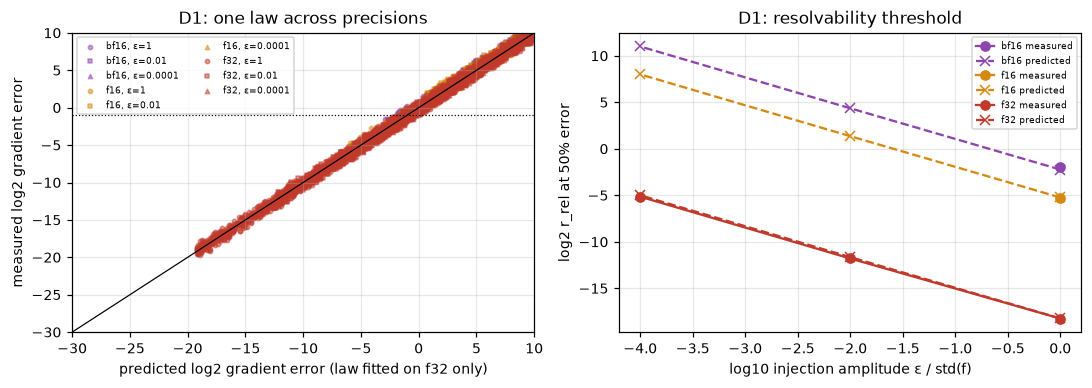

D2 parameter-side spectrum, unary deg 5 (structural null directions excluded from kappa):
 d  P  rank  null  log2_kappa_eff resolved_bf16 resolved_f16 resolved_f32
 1 18    11     7             6.5         11/11        11/11        11/11
 2 36    27     9             4.9         27/27        27/27        27/27
 3 54    43    11             6.4         43/43        43/43        43/43
 4 72    59    13             4.7         59/59        59/59        59/59
 5 90    75    15             4.0         75/75        75/75        75/75


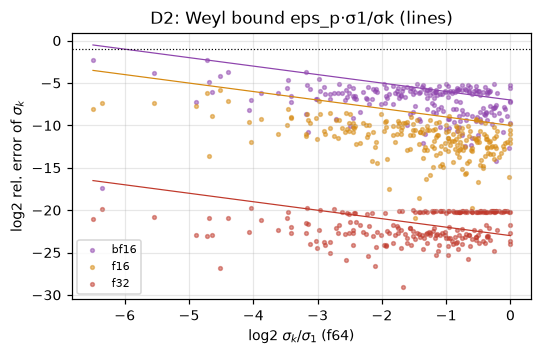

In [5]:
# ===== Part D1 analysis: one law, fitted on f32 only, must predict bf16 and f16 =====
def xpred(df, b):   # predictor without the constant a: log2 eps_p - log2 r_rel + log2(1 + b/eps)
    return np.array([LOG2EPS[p] for p in df.prec]) - df.log2r_rel.values + np.log2(1 + b / df.eps.values)

def fit_law(df):
    best = None
    for b in np.logspace(-8, 6, 281):
        x = xpred(df, b); a = np.median(df.log2err.values - x); res = df.log2err.values - x - a
        sse = np.mean(np.abs(res))
        if best is None or sse < best[2]: best = (a, b, sse)
    return best

D["ok"] = ~D.zero_grad & np.isfinite(D.log2err)
win = lambda df: df[df.ok & (df.log2err > -18) & (df.log2err < 6)]       # linear-error window
f32w = win(D[D.prec == "f32"])
a_fit, b_fit, mad = fit_law(f32w)
for _ in range(2):   # drop cells whose f64 reference itself is predicted to be inaccurate (< 8 bits margin)
    ref_ok = (a_fit + LOG2EPS["f64"] - D.log2r_rel + np.log2(1 + b_fit / D.eps)) < -8
    f32w = win(D[(D.prec == "f32") & ref_ok]); a_fit, b_fit, mad = fit_law(f32w)
D["ref_ok"] = ref_ok
D["log2err_pred"] = a_fit + xpred(D, b_fit)
print(f"law fitted on f32 only: log2 err = {a_fit:.2f} + log2 eps_p - log2 r_rel + log2(1 + {b_fit:.2e}/eps)   (MAD {mad:.2f} bits)")
if b_fit > 10 * max(D_EPS):
    print(f"   -> b >> all eps: the forward-rounding term dominates everywhere, i.e. log2 err = {a_fit + np.log2(b_fit):.2f} "
          f"+ log2 eps_p - log2 r_rel - log2 eps  (a and b are only identified through a + log2 b)")
print(f"cells dropped (f64 reference not trustworthy): {int((~D.ref_ok).sum() / len(D_PRECS))} per precision | "
      f"f16 gradients that underflowed to exactly 0: {int(D[(D.prec=='f16')].zero_grad.sum())}")

D1_summary = []
for p in D_PRECS:
    w = win(D[(D.prec == p) & D.ref_ok])
    if len(w) < 5: continue
    x = xpred(w, b_fit); slope, icpt = np.polyfit(x, w.log2err.values, 1)
    resid = w.log2err.values - (a_fit + x)
    D1_summary.append(dict(prec=p, n=len(w), slope=slope, median_resid_bits=np.median(resid), mad_bits=np.median(np.abs(resid)),
                           fitted_on="f32" if p == "f32" else "predicted"))
D1S = pd.DataFrame(D1_summary); print(D1S.to_string(index=False, float_format=lambda v: f"{v:.2f}"))

# thresholds: log2 r_rel where the error reaches 0.5 (gradient direction no longer trustworthy)
def thr_measured(df):
    df = df[df.ref_ok]
    x, y = df.log2r_rel.values, (df.log2err.values < -1) & df.ok.values
    if y.all() or (~y).all(): return np.nan
    xs = np.sort(np.unique(x))
    best, bt = -1, np.nan
    for t in xs:                       # threshold maximising classification accuracy (robust, no model)
        acc = np.mean((x >= t) == y)
        if acc > best: best, bt = acc, t
    return bt
D1T = []
for p in D_PRECS:
    for eps in D_EPS:
        sub = D[(D.prec == p) & (D.eps == eps)]
        D1T.append(dict(prec=p, eps=eps, thr_measured=thr_measured(sub),
                        thr_predicted=a_fit + LOG2EPS[p] + np.log2(1 + b_fit / eps) + 1))
D1T = pd.DataFrame(D1T); D1T["delta_bits"] = D1T.thr_measured - D1T.thr_predicted
D1T["note"] = np.where(D1T.thr_predicted > 0, "no cell resolvable (pred > 0)", "")
print(D1T.to_string(index=False, formatters={"eps": lambda v: f"{v:g}"}, float_format=lambda v: f"{v:.1f}"))
D.to_csv(D_CSV, index=False)

fig, axs = plt.subplots(1, 2, figsize=(10, 3.6))
mk = {1.0: "o", 1e-2: "s", 1e-4: "^"}
for p in D_PRECS:
    for eps in D_EPS:
        s = D[(D.prec == p) & (D.eps == eps) & D.ok & D.ref_ok]
        axs[0].scatter(s.log2err_pred, s.log2err, s=8, alpha=0.5, marker=mk[eps], color=COL[p], label=f"{p}, ε={eps:g}")
lim = [-30, 10]; axs[0].plot(lim, lim, "k-", lw=0.8); axs[0].set_xlim(lim); axs[0].set_ylim(lim)
axs[0].axhline(-1, color="k", ls=":", lw=0.8)
axs[0].set_xlabel("predicted log2 gradient error (law fitted on f32 only)"); axs[0].set_ylabel("measured log2 gradient error")
axs[0].set_title("D1: one law across precisions"); axs[0].legend(fontsize=6, ncol=2)
for p in D_PRECS:
    s = D1T[D1T.prec == p]
    axs[1].plot(np.log10(s.eps), s.thr_measured, "o-", color=COL[p], label=f"{p} measured")
    axs[1].plot(np.log10(s.eps), s.thr_predicted, "x--", color=COL[p], label=f"{p} predicted")
axs[1].set_xlabel("log10 injection amplitude ε / std(f)"); axs[1].set_ylabel("log2 r_rel at 50% error")
axs[1].set_title("D1: resolvability threshold"); axs[1].legend(fontsize=6)
plt.tight_layout(); plt.savefig(f"{RESULTS_DIR}/figD1_law.pdf"); plt.show()

# ===== Part D2: parameter-side spectrum of the data Jacobian, unary degree 5 =====
D2rows = []
for d in D2_DIMS:
    L = 5; ab = ENC["unary"](L); P = n_params(L, d, 1)
    th = init_theta(jax.random.PRNGKey(5 + d), L, d); al = alpha_array(ab, d)
    N = max(20 * P, 2000)
    X = jax.random.uniform(jax.random.PRNGKey(99 + d), (N, d), minval=0, maxval=2 * np.pi, dtype=jnp.float64)
    S = {}
    for p in ["bf16", "f16", "f32", "f64"]:
        Jp = data_jacobian(X.astype(DT[p]), th.astype(DT[p]), al.astype(DT[p]))
        S[p] = np.linalg.svd(np.asarray(Jp, dtype=np.float64), compute_uv=False)
    s64 = S["f64"]
    for p in S:
        relerr = np.abs(S[p] - s64) / s64
        for k in range(P):
            D2rows.append(dict(d=d, P=P, k=k, prec=p, log2_s_rel=np.log2(s64[k] / s64[0]), log2_relerr=np.log2(relerr[k] + 1e-300)))
D2 = pd.DataFrame(D2rows); D2.to_csv(f"{RESULTS_DIR}/partD2_spectrum.csv", index=False)
NULL = -40.0      # sigma_k/sigma_1 below 2^-40 in f64 = structural null direction (dead / gauge-redundant parameter)
D2S = []
for d in D2_DIMS:
    s64 = D2[(D2.d == d) & (D2.prec == "f64")]
    nonnull = s64.log2_s_rel > NULL
    row = dict(d=d, P=int(s64.P.iloc[0]), rank=int(nonnull.sum()), null=int((~nonnull).sum()),
               log2_kappa_eff=float(-s64.log2_s_rel[nonnull].min()))
    for p in ["bf16", "f16", "f32"]:
        e = D2[(D2.d == d) & (D2.prec == p)].log2_relerr.values[nonnull.values]
        row[f"resolved_{p}"] = f"{int((e < -1).sum())}/{int(nonnull.sum())}"
    D2S.append(row)
D2S = pd.DataFrame(D2S); D2S.to_csv(f"{RESULTS_DIR}/partD2_summary.csv", index=False)
print("D2 parameter-side spectrum, unary deg 5 (structural null directions excluded from kappa):")
print(D2S.to_string(index=False, float_format=lambda v: f"{v:.1f}"))
fig, ax = plt.subplots(figsize=(5, 3.3))
for p in ["bf16", "f16", "f32"]:
    s = D2[(D2.prec == p) & (D2.log2_s_rel > NULL)]
    ax.scatter(s.log2_s_rel, s.log2_relerr, s=6, alpha=0.5, color=COL[p], label=p)
    xx = np.linspace(s.log2_s_rel.min(), 0, 20); ax.plot(xx, LOG2EPS[p] - xx, color=COL[p], lw=0.8)
ax.axhline(-1, color="k", ls=":", lw=0.8)
ax.set_xlabel(r"log2 $\sigma_k/\sigma_1$ (f64)"); ax.set_ylabel(r"log2 rel. error of $\sigma_k$"); ax.legend(fontsize=7)
ax.set_title("D2: Weyl bound eps_p·σ1/σk (lines)")
plt.tight_layout(); plt.savefig(f"{RESULTS_DIR}/figD2_spectrum.pdf"); plt.show()

## Part E — training verdict: injection at the teacher, GD vs Adam vs LM oracle, f32 vs f64

In [6]:
# ===== Part E: does the optimiser pick up an injected cell?  Start AT the teacher theta*. =====
# target y = f* + eps*std(f*)*u_omega  (u = unit-RMS cosine in one cell, generally NOT in the model's span)
# q      = 1 - L_T/L_0  (learned fraction of the injected loss, evaluated in f64)
# q_lin  = ||P_J u||^2 / ||u||^2  (first-order reachable fraction; P_J = projector onto span of the f64 data Jacobian)
# eta    = q / q_lin
# GD linear theory (exact, f64, no fitting): eta_GDlin(T) from the singular spectrum and the GD step size.
def loss_p(th, X, y, al): return jnp.mean((model_batch(X, th, al) - y) ** 2)
FB_cells = jax.jit(jax.vmap(model_batch, in_axes=(None, 0, None)))          # (C,..) thetas -> (C, N)

def run_first_order(opt, th0, X, Y, al, p, T_list):
    dt = DT[p]
    params = jnp.broadcast_to(th0, (Y.shape[0],) + th0.shape).astype(dt)
    Xp, Yp, alp = X.astype(dt), Y.astype(dt), al.astype(dt)
    state = jax.vmap(opt.init)(params)
    vg = jax.vmap(jax.grad(loss_p), in_axes=(0, None, 0, None))
    @jax.jit
    def step(params, state):
        g = vg(params, Xp, Yp, alp)
        upd, state = jax.vmap(opt.update)(g, state, params)
        return optax.apply_updates(params, upd), state
    out, t = {}, 0
    for T in sorted(T_list):
        while t < T:
            params, state = step(params, state); t += 1
        out[T] = np.asarray(params, dtype=np.float64)
    return out

def run_gauss_newton(th0, X, Y, al, p, iters):
    """Levenberg-Marquardt oracle, every op (Jacobian, residual, SVD, step, acceptance test) in precision p.
    Singular values below 64 eps_p * s_max are dropped: structural null directions sit at ~eps_p and must be cut.
    A step is accepted only if the loss (in p) decreases; mu adapts x3 / /3."""
    dt = DT[p]; rc = 2.0 ** (LOG2EPS[p] + 6)
    Xp, alp = X.astype(dt), al.astype(dt)
    ths = []
    for c in range(Y.shape[0]):
        th = th0.astype(dt); y = jnp.asarray(Y[c]).astype(dt)
        res = model_batch(Xp, th, alp) - y; loss = jnp.mean(res ** 2); mu = None
        for _ in range(iters):
            J = data_jacobian(Xp, th, alp)
            Uj, s, Vt = jnp.linalg.svd(J, full_matrices=False)
            keep = s > rc * s[0]
            mu = (1e-3 * s[0] ** 2) if mu is None else mu
            proj = Uj.T @ res
            for _try in range(12):
                fac = jnp.where(keep, s / (s ** 2 + mu), 0.0)
                cand = th - (Vt.T @ (fac * proj)).reshape(th.shape).astype(dt)
                rc_ = model_batch(Xp, cand, alp) - y; lc = jnp.mean(rc_ ** 2)
                if lc < loss:
                    th, res, loss, mu = cand, rc_, lc, mu / 3; break
                mu = mu * 3
        ths.append(np.asarray(th, dtype=np.float64))
    return np.stack(ths)

E_CSV = f"{RESULTS_DIR}/partE_cells.csv"
Erows = pd.read_csv(E_CSV).to_dict("records") if os.path.exists(E_CSV) else []
done_E = {(r["enc"], r["d"], r["L"], r["seed"], r["opt"], r["prec"], r["eps"]) for r in Erows}
OPTS = {"gd": None, **{f"adam_lr{lr:g}_eps{ae:g}": (lr, ae) for lr, ae in E_ADAM}, "gn": "gn"}
for enc, d, L in E_CONFIGS:
    ab = ENC[enc](L); K = degree(ab)
    for s in range(E_SEEDS):
        th = init_theta(jax.random.PRNGKey(333 + 1000 * d + 10 * L + s), L, d); al = alpha_array(ab, d)
        X, M = grid(K, d); N = X.shape[0]
        fstar = np.asarray(_FB(X, th, al)); sd = fstar.std()
        Jd = np.asarray(data_jacobian(X, th, al))
        F, r = cell_row_norms(jnp.asarray(Jd), M, d, K)
        rng = np.random.default_rng(100 + s)
        idx = pick_cells(F, r, E_NPB, D_BIN, D_LO, rng)
        U = np.stack([injection(X, F[i], rng.uniform(0, 2 * np.pi)) for i in idx])
        Us, S, _ = np.linalg.svd(Jd, full_matrices=False)
        keep = S / S[0] > 2.0 ** -40
        Us, S = Us[:, keep], S[keep]
        coef = U @ Us                                                     # (C, rank)
        q_lin = np.sum(coef ** 2, 1) / np.sum(U ** 2, 1)
        lam = (2.0 / N) * S ** 2; lr_gd = 0.9 / lam[0]
        def eta_gd_lin(T):
            rem = np.sum(U ** 2, 1) - np.sum(coef ** 2, 1) + np.sum(coef ** 2 * (1 - lr_gd * lam) ** (2 * T), 1)
            return (1 - rem / np.sum(U ** 2, 1)) / q_lin
        lr_rel = np.log2(r[idx] / r.max()); lrho = log2rho_of(F[idx], ab)
        for eps, oname, p in itertools.product(E_EPS, OPTS, E_PRECS):
                ospec = OPTS[oname]
                if (enc, d, L, s, oname, p, eps) in done_E: continue
                Y = fstar[None] + eps * sd * U
                L0 = (eps * sd) ** 2 * np.mean(U ** 2, 1)
                t0 = time.time()
                if ospec == "gn":
                    res = {E_GN_ITERS: run_gauss_newton(th, X, Y, al, p, E_GN_ITERS)}
                else:
                    opt = optax.sgd(lr_gd) if ospec is None else optax.adam(ospec[0], eps=ospec[1])
                    res = run_first_order(opt, th, X, Y, al, p, E_T)
                for T, ths in res.items():
                    pred = np.asarray(FB_cells(X, jnp.asarray(ths), al))
                    LT = np.mean((pred - Y) ** 2, 1)
                    q = 1 - LT / L0
                    eg = eta_gd_lin(T) if oname == "gd" else np.full(len(idx), np.nan)
                    for j, i in enumerate(idx):
                        Erows.append(dict(enc=enc, d=d, L=L, seed=s, opt=oname, prec=p, T=T, eps=eps, cell=str(tuple(F[i])),
                                          log2r_rel=lr_rel[j], log2rho=lrho[j], q=q[j], q_lin=q_lin[j], eta=q[j] / q_lin[j],
                                          eta_gd_lin=eg[j], lr_gd=lr_gd))
                done_E.add((enc, d, L, s, oname, p, eps))
                pd.DataFrame(Erows).to_csv(E_CSV, index=False)
                print(f"E {enc} d={d} L={L} seed={s} eps={eps:g} {oname:<22} {p}: {len(idx)} cells, {time.time()-t0:.0f}s", flush=True)
E = pd.DataFrame(Erows)

E unary d=1 L=40 seed=0 eps=0.01 gd                     f32: 29 cells, 12s
E unary d=1 L=40 seed=0 eps=0.01 gd                     f64: 29 cells, 22s
E unary d=1 L=40 seed=0 eps=0.01 adam_lr0.001_eps1e-08  f32: 29 cells, 12s
E unary d=1 L=40 seed=0 eps=0.01 adam_lr0.001_eps1e-08  f64: 29 cells, 22s
E unary d=1 L=40 seed=0 eps=0.01 adam_lr0.0001_eps1e-08 f32: 29 cells, 12s
E unary d=1 L=40 seed=0 eps=0.01 adam_lr0.0001_eps1e-08 f64: 29 cells, 22s
E unary d=1 L=40 seed=0 eps=0.01 adam_lr0.0001_eps1e-30 f32: 29 cells, 12s
E unary d=1 L=40 seed=0 eps=0.01 adam_lr0.0001_eps1e-30 f64: 29 cells, 22s
E unary d=1 L=40 seed=0 eps=0.01 adam_lr1e-06_eps1e-08  f32: 29 cells, 12s
E unary d=1 L=40 seed=0 eps=0.01 adam_lr1e-06_eps1e-08  f64: 29 cells, 22s
E unary d=1 L=40 seed=0 eps=0.01 gn                     f32: 29 cells, 364s
E unary d=1 L=40 seed=0 eps=0.01 gn                     f64: 29 cells, 195s
E unary d=1 L=40 seed=0 eps=0.0001 gd                     f32: 29 cells, 12s
E unary d=1 L=40 seed

KeyboardInterrupt: 

In [ ]:
# ===== Part E analysis =====
E["cfg"] = E.enc + " d=" + E.d.astype(str) + " L=" + E.L.astype(str)
Ev = E[E.q_lin > 0.05].copy()           # cells with a non-trivial first-order reachable part
print(f"cells with q_lin > 0.05: {Ev.cell.nunique()} of {E.cell.nunique()} (per config/seed); "
      f"q_lin median by log2 r_rel bin:")
E["rbin"] = (np.floor(E.log2r_rel / 8) * 8).astype(int); Ev["rbin"] = (np.floor(Ev.log2r_rel / 8) * 8).astype(int)
print(E.drop_duplicates(["cfg", "seed", "cell"]).groupby("rbin").q_lin.median().to_string(float_format=lambda v: f"{v:.3f}"))

def thr_eta(df):
    x, y = df.log2r_rel.values, df.eta.values > 0.5
    if y.all(): return -np.inf
    if (~y).all(): return np.inf
    best, bt = -1, np.nan
    for t in np.unique(x):
        acc = np.mean((x >= t) == y)
        if acc > best: best, bt = acc, t
    return bt

rows = []
for (eps, opt, p, T), g in Ev.groupby(["eps", "opt", "prec", "T"]):
    row = dict(eps=eps, opt=opt, prec=p, T=T, n=len(g), thr_log2r=thr_eta(g), eta_med=g.eta.median(),
               eta_low=g[g.log2r_rel < -16].eta.median())
    if opt == "gd": row["med_abs_dev_from_linear_theory"] = np.median(np.abs(g.eta - g.eta_gd_lin))
    rows.append(row)
ES = pd.DataFrame(rows); ES.to_csv(f"{RESULTS_DIR}/partE_summary.csv", index=False)
print("eta = learned / first-order-reachable; thr = log2 r_rel below which eta < 0.5 (-inf: all cells learned)")
print(ES.to_string(index=False, formatters={"eps": lambda v: f"{v:g}"}, float_format=lambda v: f"{v:.2f}"))

# paired precision test: same cell, same optimiser, same T, f32 vs f64
pv = Ev.pivot_table(index=["cfg", "seed", "cell", "eps", "opt", "T", "rbin"], columns="prec", values="eta").dropna().reset_index()
pv["deta"] = pv.f32 - pv.f64
prec_binds = {}
print("paired f32 - f64 difference in eta (median per log2 r_rel bin; |.| > 0.2 = precision matters):")
for (eps, opt), g in pv.groupby(["eps", "opt"]):
    Tm = g["T"].max(); gg = g[g["T"] == Tm]
    per_bin = gg.groupby("rbin").deta.agg(["median", "size"])
    per_bin = per_bin[per_bin["size"] >= 3]
    prec_binds[(opt, eps)] = bool((per_bin["median"].abs() > 0.2).any())
    print(f"   eps={eps:<6g} {opt:<24} T={Tm}: " + ", ".join(f"[{b},{b+8}): {m:+.2f} (n={n})" for b, (m, n) in per_bin.iterrows()))

opts = list(OPTS)
fig, axs = plt.subplots(len(E_EPS), len(opts), figsize=(3.3 * len(opts), 3.0 * len(E_EPS)), sharey=True, squeeze=False)
for row, eps in enumerate(E_EPS):
    for ax, opt in zip(axs[row], opts):
        g = Ev[(Ev.opt == opt) & (Ev.eps == eps)]
        Ts = sorted(g["T"].unique())
        for p in E_PRECS:
            for k, T in enumerate(Ts):
                s_ = g[(g.prec == p) & (g["T"] == T)]
                ax.scatter(s_.log2r_rel, s_.eta, s=7, alpha=0.5, color=COL[p], marker="os^"[k % 3], label=f"{p} T={T}")
        if opt == "gd":
            for T in Ts:
                s_ = g[(g.prec == "f64") & (g["T"] == T)].sort_values("log2r_rel")
                ax.plot(s_.log2r_rel, s_.eta_gd_lin, "k-", lw=0.6, alpha=0.7)
        thr_vis = a_fit + LOG2EPS["f32"] + np.log2(1 + b_fit / eps) + 1 if "a_fit" in globals() else None
        if thr_vis is not None: ax.axvline(thr_vis, color=COL["f32"], ls="--", lw=0.8)
        ax.axhline(0.5, color="k", ls=":", lw=0.8); ax.set_title(f"{opt}, eps={eps:g}", fontsize=7)
        ax.set_xlabel("log2 r_rel of injected cell")
    axs[row][0].set_ylabel("eta = q / q_lin")
axs[0][0].legend(fontsize=5)
plt.tight_layout(); plt.savefig(f"{RESULTS_DIR}/figE_learned.pdf"); plt.show()

## Parts F and G — random-init stall vs over-parameterisation; fair trainable-frequency test

In [ ]:
# ===== shared trainer for F and G (f64, Adam, seeds vmapped) =====
def _loss_fg(params, X, y, al_fixed, trainable):
    al = params["alpha"] if trainable else al_fixed
    return jnp.mean((model_batch(X, params["theta"], al) - y) ** 2)

def train_seeds(params0, X, y, al_fixed, trainable, lr, steps):
    opt = optax.adam(lr); state = jax.vmap(opt.init)(params0)
    vg = jax.vmap(jax.value_and_grad(_loss_fg), in_axes=(0, 0, 0, 0, None))
    @jax.jit
    def step(params, state):
        l, g = vg(params, X, y, al_fixed, trainable)
        upd, state = jax.vmap(opt.update)(g, state, params)
        return optax.apply_updates(params, upd), state, l
    params = params0
    for _ in range(steps):
        params, state, l = step(params, state)
    g = jax.vmap(jax.grad(_loss_fg), in_axes=(0, 0, 0, 0, None))(params, X, y, al_fixed, trainable)
    gnorm = np.sqrt(np.asarray(jax.tree_util.tree_reduce(lambda a, b: a + b,
                    jax.tree_util.tree_map(lambda t: jnp.sum(t ** 2, axis=tuple(range(1, t.ndim))), g))))
    return params, np.asarray(l), gnorm

def nmse(params, X, y, al_fixed, trainable):
    f = jax.vmap(_loss_fg, in_axes=(0, 0, 0, 0, None))
    return np.asarray(f(params, X, y, al_fixed, trainable)) / np.asarray(jnp.var(y, axis=1))

def data(key, S, N, d):
    return jax.random.uniform(key, (S, N, d), minval=0, maxval=2 * np.pi, dtype=jnp.float64)

# ===== Part F: does over-parameterisation (more trainable blocks, same degree) rescue random init? =====
F_CSV = f"{RESULTS_DIR}/partF.csv"
Frows = pd.read_csv(F_CSV).to_dict("records") if os.path.exists(F_CSV) else []
done_F = {(r["d"], r["tbl"]) for r in Frows}
for d in F_DIMS:
    ab = ENC["unary"](F_L)
    kT, kX, kE, kS = jax.random.split(jax.random.PRNGKey(4242 + d), 4)
    tT = jnp.stack([init_theta(k, F_L, d, 1) for k in jax.random.split(kT, F_SEEDS)])      # teacher: tbl = 1, fixed for all students
    al = jnp.broadcast_to(alpha_array(ab, d), (F_SEEDS, F_L, d))
    Xtr, Xte = data(kX, F_SEEDS, F_N, d), data(kE, F_SEEDS, F_N, d)
    ytr = jnp.stack([model_batch(Xtr[i], tT[i], al[i]) for i in range(F_SEEDS)])
    yte = jnp.stack([model_batch(Xte[i], tT[i], al[i]) for i in range(F_SEEDS)])
    for tbl in F_TBL:
        if (d, tbl) in done_F: continue
        t0 = time.time()
        th0 = jnp.stack([init_theta(k, F_L, d, tbl) for k in jax.random.split(jax.random.fold_in(kS, tbl), F_SEEDS)])
        p0 = {"theta": th0, "alpha": al}
        p, ltr, gn = train_seeds(p0, Xtr, ytr, al, False, 0.01, F_STEPS)
        te = nmse(p, Xte, yte, al, False); tr = ltr / np.asarray(jnp.var(ytr, axis=1))
        P = n_params(F_L, d, tbl)
        for s in range(F_SEEDS):
            Frows.append(dict(d=d, tbl=tbl, P=P, dla=4 ** d - 1, seed=s, test_nmse=te[s], train_nmse=tr[s],
                              gnorm_over_var=gn[s] / float(jnp.var(ytr[s]))))
        pd.DataFrame(Frows).to_csv(F_CSV, index=False)
        print(f"F d={d} tbl={tbl} P={P} (4^d-1={4**d-1}): success {np.mean(te < F_SUCCESS):.2f}, "
              f"median test nMSE {np.median(te):.2e}, {time.time()-t0:.0f}s", flush=True)
Fd = pd.DataFrame(Frows)
FS = Fd.groupby(["d", "tbl", "P", "dla"]).agg(success=("test_nmse", lambda v: np.mean(v < F_SUCCESS)),
        test_med=("test_nmse", "median"), train_med=("train_nmse", "median"), gnorm_med=("gnorm_over_var", "median")).reset_index()
print(FS.to_string(index=False, float_format=lambda v: f"{v:.2e}"))

# ===== Part G: fair trainable-frequency test (additive off-lattice offsets, near and random init) =====
G_CSV = f"{RESULTS_DIR}/partG.csv"
Grows = pd.read_csv(G_CSV).to_dict("records") if os.path.exists(G_CSV) else []
done_G = {(r["arm"], r["d"], r["jitter"], r["init"]) for r in Grows}
for d in G_DIMS:
    for jit_ in G_JITTER:
        for arm, (enc, L, trainable) in G_ARMS.items():
            for init in G_INITS:
                if (arm, d, jit_, init) in done_G: continue
                t0 = time.time()
                k = jax.random.PRNGKey(777 + 100 * d + int(1000 * jit_))      # same teacher/data for all arms with the same encoding
                kT, kA, kX, kE, kS = jax.random.split(jax.random.fold_in(k, 0 if enc == "unary" else 1), 5)
                base = jnp.broadcast_to(alpha_array(ENC[enc](L), d), (G_SEEDS, L, d))
                aT = base + jax.random.uniform(kA, base.shape, minval=-jit_, maxval=jit_, dtype=jnp.float64)
                tT = jnp.stack([init_theta(kk, L, d, G_TBL) for kk in jax.random.split(kT, G_SEEDS)])
                Xtr, Xte = data(kX, G_SEEDS, G_N, d), data(kE, G_SEEDS, G_N, d)
                ytr = jnp.stack([model_batch(Xtr[i], tT[i], aT[i]) for i in range(G_SEEDS)])
                yte = jnp.stack([model_batch(Xte[i], tT[i], aT[i]) for i in range(G_SEEDS)])
                if init == "near":
                    th0 = tT + 0.1 * jax.random.normal(kS, tT.shape, dtype=jnp.float64)
                else:
                    th0 = jnp.stack([init_theta(kk, L, d, G_TBL) for kk in jax.random.split(kS, G_SEEDS)])
                p0 = {"theta": th0, "alpha": base}
                p, ltr, gn = train_seeds(p0, Xtr, ytr, base, trainable, 0.01, G_STEPS)
                te = nmse(p, Xte, yte, base, trainable)
                a_err = np.abs(np.asarray(p["alpha"]) - np.asarray(aT)).reshape(G_SEEDS, -1) if trainable else None
                for s in range(G_SEEDS):
                    Grows.append(dict(arm=arm, enc=enc, trainable=trainable, d=d, jitter=jit_, init=init, seed=s, test_nmse=te[s],
                                      alpha_err_med=np.median(a_err[s]) if trainable else np.nan,
                                      alpha_frac_within_0p1=np.mean(a_err[s] < 0.1) if trainable else np.nan,
                                      alpha_offset_med=float(np.median(np.abs(np.asarray(aT[s] - base[s]))))))
                pd.DataFrame(Grows).to_csv(G_CSV, index=False)
                print(f"G d={d} jitter={jit_} {arm:<14} {init:<6}: median test nMSE {np.median(te):.2e}, {time.time()-t0:.0f}s", flush=True)
Gd = pd.DataFrame(Grows)
GS = Gd.pivot_table(index=["init", "jitter", "d"], columns="arm", values="test_nmse", aggfunc="median")
print("G: median test nMSE (f64, Adam)"); print(GS.to_string(float_format=lambda v: f"{v:.1e}"))
GT = Gd[Gd.trainable].pivot_table(index=["init", "jitter", "d"], columns="arm", values="alpha_frac_within_0p1", aggfunc="median")
print("G: fraction of trainable prefactors that reached the teacher's value (|err| < 0.1)"); print(GT.to_string(float_format=lambda v: f"{v:.2f}"))

fig, axs = plt.subplots(1, 2, figsize=(10, 3.3))
for (d,), g in FS.groupby(["d"]):
    axs[0].plot(g.P / g.dla, g.success, "o-", label=f"d={d}")
axs[0].set_xscale("log"); axs[0].set_xlabel("P / (4^d - 1)"); axs[0].set_ylabel(f"success rate (test nMSE < {F_SUCCESS:g})")
axs[0].set_title("F: over-parameterisation vs random-init stall"); axs[0].legend(fontsize=7)
for arm in G_ARMS:
    for init, ls in (("near", "-"), ("random", "--")):
        s = Gd[(Gd.arm == arm) & (Gd.init == init)].groupby("jitter").test_nmse.median()
        axs[1].semilogy(s.index, s.values, ls, marker="o" if "unary" in arm else "s",
                        mfc="none" if "fixed" in arm else None, color=plt.cm.tab10(list(G_ARMS).index(arm)), label=f"{arm} {init}")
axs[1].set_xlabel("additive prefactor offset δ (pooled over d)"); axs[1].set_ylabel("median test nMSE"); axs[1].legend(fontsize=6)
axs[1].set_title("G: trainable vs fixed frequencies")
plt.tight_layout(); plt.savefig(f"{RESULTS_DIR}/figFG.pdf"); plt.show()

## Verdicts (rules fixed before the run, see top)

In [ ]:
# ===== Pre-registered verdicts =====
print("=" * 90)
# V1: gradient-visibility law
okV1 = len(D1S) == len(D_PRECS) and all(abs(D1S.slope - 1) <= 0.15) and \
       all(D1S[D1S.fitted_on == "predicted"].median_resid_bits.abs() <= 2)
print(f"V1 gradient-visibility law (fit on f32, predict bf16/f16): {'PASS' if okV1 else 'FAIL'}")
print(D1S.to_string(index=False, float_format=lambda v: f"{v:.2f}"))

# map the law to input dimension: corner cell of unary degree 5, using r_rel ~ rho^gamma fitted on the D cells
gfit = D[(D.prec == "f32") & (D.eps == D_EPS[0])].drop_duplicates(["enc", "d", "L", "seed", "cell"])
gamma, c0 = np.polyfit(gfit.log2rho, gfit.log2r_rel, 1)
_, w5 = redundancy_1d(ENC["unary"](5)); l1 = np.log2(w5.min() / w5.max())
rows = []
for p in ["bf16", "f16", "f32", "f64"]:
    for eps in D_EPS:
        thr = a_fit + LOG2EPS[p] + np.log2(1 + b_fit / eps) + 1          # log2 r_rel at which the gradient error reaches 1/2
        rows.append(dict(prec=p, eps=eps, thr_log2r_rel=thr, d_star_corner=(thr - c0) / (gamma * l1) if thr < 0 else 0.0,
                         status="validated" if p in D_PRECS else "extrapolated (eps-scaling validated on 16/32-bit)"))
DSTAR = pd.DataFrame(rows); DSTAR.to_csv(f"{RESULTS_DIR}/verdict_dstar.csv", index=False)
print(f"   r_rel ~ rho^gamma on these cells: gamma = {gamma:.2f}, c = {c0:.2f}; corner cell of unary deg 5: log2 rho = {l1:.2f} per dimension")
print("   d* = input dimension at which the gradient of a corner-cell target component of amplitude eps*std(f) stops being resolvable:")
print(DSTAR.to_string(index=False, formatters={"eps": lambda v: f"{v:g}"}, float_format=lambda v: f"{v:.1f}"))

# V2: parameter side
print("V2 parameter-side spectrum (unary deg 5): every non-null parameter direction resolved in precision p?")
print(D2S.to_string(index=False, float_format=lambda v: f"{v:.1f}"))

# V3: training
gd = ES[ES.opt == "gd"]
okGD = bool((gd.med_abs_dev_from_linear_theory <= 0.05).all())
print(f"V3a GD follows exact f64 linear theory (median |eta - eta_lin| <= 0.05) in f32 and f64: {'YES' if okGD else 'NO'}")
print("V3b precision binds training (paired f32 vs f64, |median d_eta| > 0.2 in some r_rel bin):")
for (o, eps), v_ in prec_binds.items(): print(f"     eps={eps:<6g} {o:<24} {'YES' if v_ else 'no'}")
Tm = ES.groupby(["eps", "opt"])["T"].transform("max")
print("V3c learnability threshold (log2 r_rel, eta < 0.5 below) at the largest budget per optimiser:")
print(ES[ES["T"] == Tm][["eps", "opt", "prec", "T", "thr_log2r"]].to_string(index=False, formatters={"eps": lambda v: f"{v:g}"},
      float_format=lambda v: f"{v:.1f}"))
for eps in E_EPS:
    g64 = gd[(gd.prec == "f64") & (gd.eps == eps)].sort_values("T")
    if len(g64) < 2: continue
    shift = g64.thr_log2r.iloc[-1] - g64.thr_log2r.iloc[0]
    pred_shift = -0.5 * np.log2(g64["T"].iloc[-1] / g64["T"].iloc[0])
    print(f"V3d eps={eps:g}: GD threshold shift T={g64['T'].iloc[0]} -> {g64['T'].iloc[-1]}: {shift:+.1f} bits "
          f"(budget law with r_rel ~ sigma predicts about {pred_shift:+.1f})")
# A paired f32-vs-f64 test can only show a precision effect on cells that f64 DOES learn and that lie below the f32
# visibility threshold. Count them per amplitude.
any_power = False
for eps in E_EPS:
    thr32 = a_fit + LOG2EPS["f32"] + np.log2(1 + b_fit / eps) + 1
    sub = Ev[(Ev.log2r_rel < thr32) & (Ev.prec == "f64") & (Ev.eps == eps)]
    sub = sub[sub["T"] == sub.groupby("opt")["T"].transform("max")]
    n_pow = sub[sub.eta > 0.5].drop_duplicates(["cfg", "seed", "cell"]).shape[0]
    n_all = E[(E.prec == "f32") & (E.opt == "gd") & (E.eps == eps) & (E.log2r_rel < thr32)].drop_duplicates(["cfg", "seed", "cell"]).shape[0]
    any_power |= n_pow >= 5
    print(f"V3e eps={eps:g}: cells below the f32 visibility threshold (log2 r_rel < {thr32:.1f}): {n_all}; "
          f"learned in f64 by some optimiser (eta > 0.5): {n_pow}  -> {'test has power' if n_pow >= 5 else 'NO POWER'}")
binds = [k for k, v_ in prec_binds.items() if v_]
if not any_power:
    print("  => The paired test has NO POWER for the f32 floor: f64 itself does not learn the cells below it within the budget,")
    print("     so f32 cannot do worse. The optimiser/budget binds before precision can. Not a test of the floor.")
elif not binds:
    print("  => Precision does NOT limit training here, although cells below the f32 visibility threshold that f64 learns")
    print("     were tested.")
else:
    print("  => Precision binds for: " + ", ".join(f"{o} (eps={e:g})" for o, e in binds) + "  -> inspect figE_learned")
print(f"     GD vs exact f64 linear theory: {'matches' if okGD else 'DEVIATES'} in both precisions.")

# V4: random-init stall
print("V4 random-init stall vs over-parameterisation (success = test nMSE < %g):" % F_SUCCESS)
print(FS[["d", "tbl", "P", "dla", "success", "test_med", "gnorm_med"]].to_string(index=False,
      formatters={"success": lambda v: f"{v:.2f}"}, float_format=lambda v: f"{v:.1e}"))

# V5: trainable frequencies
print("V5 trainable vs fixed frequencies: median test nMSE ratio fixed/trainable (> 10 = trainable clearly worth it)")
GR = pd.DataFrame({"unary": GS["unary_fixed"] / GS["unary_train"], "ternary": GS["ternary_fixed"] / GS["ternary_train"]})
print(GR.to_string(float_format=lambda v: f"{v:.1f}"))
print("=" * 90)